# Section 1 : Random Numbers 
* How to generate random numbers and python libraries 
* Monte-Carlo example 

In [1]:
# Random numbers, 1 way
import random

# Initialize the random number generator with a seed.
# Use None as seed for using the current time.
random.seed(42)

# Return the next floating point number between [0 and 1).
print(random.random())

# Return a uniformly distributed floating point number in the range [a, b].
a = 1
b = 6
print(random.uniform(a, b))

# See numpy how to generate a sequence of random numbers.

0.6394267984578837
1.1250537761133348


In [2]:
#Numpy random number 2 way 
from numpy import random
import numpy as np
x = random.randint(100) #Advantage ->Gives an array directly 

y = random.randint(100, size=(3, 5)) #Specifying the size, can be multidimensionnal array 

print(x) 


14


In [3]:
#Picking a random number in a seires 
x = random.choice([3, 5, 7, 9])
print(x) 

arr = np.array([1, 2, 3, 4, 5]) #If you just want to shuffle randomly the numbers 
random.shuffle(arr)

print(arr) 


9
[2 5 3 1 4]


In [4]:
#Can generate number according to any distribution
print(random.normal(size=(2, 3)))
print(random.binomial(n=10, p=0.5, size=10))
print(random.poisson(lam=2, size=10))
print(random.uniform(size=(2, 3)))

[[ 0.44937115 -0.96143654 -0.64960026]
 [ 0.39736204 -0.83078102 -0.95420506]]
[5 3 5 6 4 7 5 5 2 3]
[1 5 0 1 3 0 0 3 1 2]
[[0.42944601 0.02475028 0.47176565]
 [0.22225588 0.93326122 0.42804245]]


Why do we care about random numbers ? Well it tries to answer the question how do we estimate something that we know nothing about, it could an area, it could be a current value, a flux of particle etc ? By simulating all the possible outcomes, the mean and variation of a variable or a system can be measured relatively precisely without having to know much about the system, this is the heart of Monte-Carlo simulation something extremely useful in physics and science in general.  

# The Typical example : estimating pi

Can use Monte-Carlo to estimate estimate the number of points inside and outside a square \\


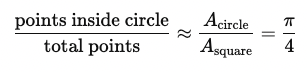


Estimated value of π with 10000 samples: 3.1224 The real value of pi is 3.141592653589793


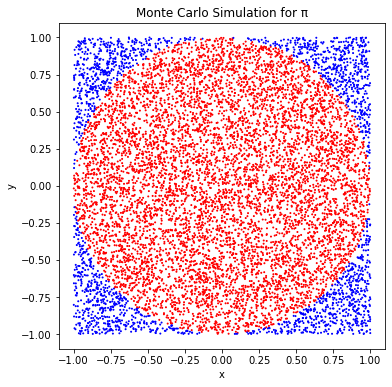

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def monte_carlo_pi(num_samples):
    x = np.random.uniform(-1, 1, num_samples)
    y = np.random.uniform(-1, 1, num_samples)
    
    distance = np.sqrt(x**2 + y**2)
    
    inside_circle = np.sum(distance <= 1)
    
    pi_estimate = (inside_circle / num_samples) * 4
    
    return pi_estimate

num_samples = 10000

pi_estimate = monte_carlo_pi(num_samples)

print(f"Estimated value of π with {num_samples} samples: {pi_estimate}"+" The real value of pi is "+str(np.pi))
x = np.random.uniform(-1, 1, num_samples)
y = np.random.uniform(-1, 1, num_samples)
plt.figure(figsize=(6, 6))
plt.scatter(x, y, c=np.sqrt(x**2 + y**2) <= 1, cmap='bwr', s=1)
plt.gca().set_aspect('equal', adjustable='box')
plt.title('Monte Carlo Simulation for π')
plt.xlabel('x')
plt.ylabel('y')
plt.show()



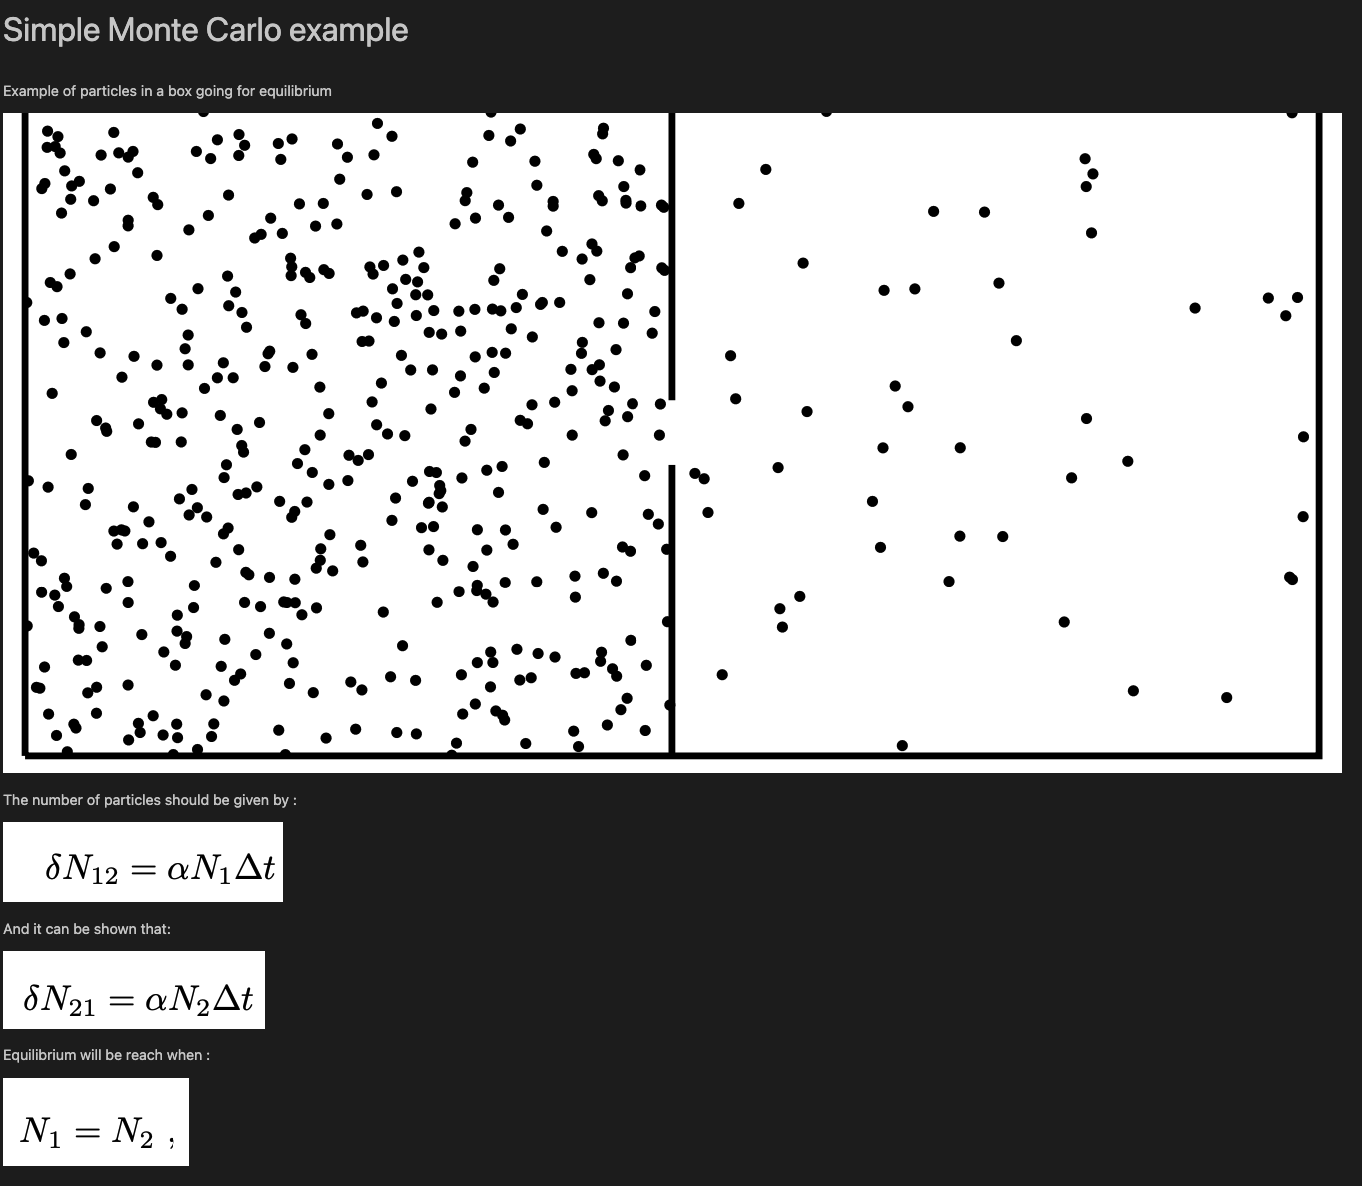

# Vectorization 
* Define has 1 dimensional array operation 
*  if can be replace with masking 
* for can be replace by updating a large array containing all the elements you need 
* Useful for the parallelization 
* Useful tool is np.vectorize 

Useful links: 

https://www.programiz.com/python-programming/numpy/vectorization



In [6]:
import numpy as np #Import relevant packages 
import matplotlib.pyplot as plt
import time

In [7]:
start = time.time() #Start the time 

array1 = [1, 2, 3, 4, 5] #Initialize simple list

for i in range(len(array1)): #Perform operation on each element of the list 
    array1[i] += 10

end = time.time()

print("For loop time:", end - start)

For loop time: 0.00012087821960449219


In [8]:
start = time.time()

array1 = np.array([1, 2, 3, 4, 5 ])

result = array1 + 10

end = time.time()

print("Total time:", end - start) #This is a bit cheating because it's using an array instead of a list ...

Total time: 0.00018286705017089844


In [31]:
%%time
array1 = 2#np.array([-1, 0, 2, 3, 4])
#Defining a simple function
def find_root_square(x):
    if x < 0:
        return 0
    else:
        return x **2
result=find_root_square(array1)

CPU times: user 6 µs, sys: 1 µs, total: 7 µs
Wall time: 8.82 µs


In [32]:
%%time
# function that returns the square of a positive number
@np.vectorize #Can defined function which will be compiles (faster execution)
def find_root_square_v(x):
    if x < 0:
        return 0
    else:
        return x **2

result=find_root_square(array1)

CPU times: user 22 µs, sys: 1 µs, total: 23 µs
Wall time: 26.9 µs


# Vectorization example (2)

Some theory : 
N : Number of particles 
T: Transmission of particles
A: Absorption of particle 
R: Reflection of particle 
Ang: Angle at which the particle is going





In [11]:
def interac(pa,ps,lam,d,N):
    """
    Function which keeps track of the what is happenning to the interactions
    """
    sr=0 # Counts for what happens
    sa=0
    st=0
    tStart=time.time()
    for k in range(N): # Go over the neutrons
            x=0 
            ang=0
            #r=np.random.random()
            while 1: # Iterate over the different neutrons
                r=np.random.random() # random number between 0 and 1
                l=-lam*np.log(r) #Exponentially distributed random number
                x+=l*np.cos(ang) # Amplitude is random 
                if x<0: 
                    sr+=1 #Reflection
                    break
                elif x>d:
                    st+=1  #Transmission
                    break

                elif r<pa: #Absoprtion
                    sa+=1
                    break
                elif pa<=r<pa+ps: #Scattering of the rangle
                    r1=np.random.random()
                    ang=np.arccos(1-(2*r1))         
    tEnd=time.time()            
    R=sr/N #Reflection coefficient
    A=sa/N
    T=st/N
    sigR=np.sqrt(R*(1-R)/(N-1)) # Error
    sigA=np.sqrt(A*(1-A)/(N-1))
    sigT=np.sqrt(T*(1-T)/(N-1))
    dt=tEnd-tStart
    print("Time per iteration",dt)
    return R,A,T,N,sigR,sigT,sigA,'string',dt # 


In [12]:

#Vectorize function
def interac_vectorize(pa,ps,lam,d,N):
   
    """
    Same function just vectorize 
    """
    tStart=time.time() 
    xpo=np.zeros(N) 
    angm=np.ones(N) 
    
    actif=np.ones(N)
    iactif,=actif.nonzero()
    testDisp=np.ones(N)
    itestDisp,=testDisp.nonzero()
    
    
    while iactif.size!=0: 
        r=np.random.random(N) 
        xpo[iactif]=xpo[iactif]-(lam*np.log(r[iactif])*angm[iactif]) 
        
        actif[iactif]=(xpo[iactif]>0)  
        
        iactif,=actif.nonzero() 
        
        
        actif[iactif]=(xpo[iactif]<d) #Update the array
        iactif,=actif.nonzero() 
        
        actif[iactif]=(r[iactif]>pa) # Update the array following a condition 
        iactif,=actif.nonzero() 
    
      
        testDisp=(r<(ps+pa)) 
        itestDisp,=testDisp.nonzero() 
        r1=np.random.random(N) 
        angm[itestDisp]=(1-(2*r1[itestDisp])) 
       
   
    sa=((xpo>0) & (xpo<d))   # Average number of absorbed the reflected, transmitted
    sr=((xpo<0))
    st=((xpo>d))
    R=sum(sr)/N 
    A=sum(sa)/N
    T=sum(st)/N
    sigR=np.sqrt(R*(1-R)/(N-1)) 
    sigA=np.sqrt(A*(1-A)/(N-1))
    sigT=np.sqrt(T*(1-T)/(N-1))
    tEnd=time.time()    
    dt=tEnd-tStart
    print("Time per iteration vectorize",dt)
    return R,A,T,N,sigR,sigT,sigA,'string',dt 

In [13]:
pa=0.4 # Probability of Absorption
ps=np.arange(0,(1-pa)+0.001,0.1) #Number of iterations 
RE=np.zeros(len(ps)) #Number of absorbed, transmitted and reflected 
AB=np.zeros(len(ps))
TR=np.zeros(len(ps))
#sigmaR=np.zeros(len(ps))
sigmaR=np.zeros(len(ps)) #Error
sigmaT=np.zeros(len(ps))
sigmaA=np.zeros(len(ps))
i=0 
for ps1 in ps: 
    R,A,T,N,sigR,sigT,sigA,g,dt1=interac_vectorize(pa,ps1,0.4,1,20000) 
    R,A,T,N,sigR,sigT,sigA,g,dt2=interac(pa,ps1,0.4,1,20000) 
    RE[i]=R 
    AB[i]=A
    TR[i]=T
    sigmaR[i]=sigR 
    #sigmaR[i]=np.sqrt(*(N-sr1)/(N-1))
    sigmaT=sigT
    sigmaA[i]=sigA
    i+=1 
print("Improvement in time",format((1-dt1/dt2)*100,'.2f')+'%')

Time per iteration vectorize 0.09912991523742676
Time per iteration 0.10489916801452637
Time per iteration vectorize 0.09541487693786621
Time per iteration 0.11222505569458008
Time per iteration vectorize 0.09402179718017578
Time per iteration 0.1159520149230957
Time per iteration vectorize 0.09489893913269043
Time per iteration 0.11845803260803223
Time per iteration vectorize 0.09691691398620605
Time per iteration 0.12407398223876953
Time per iteration vectorize 0.09210991859436035
Time per iteration 0.12648987770080566
Time per iteration vectorize 0.09581899642944336
Time per iteration 0.1235048770904541
Improvement in time 22.42%


# Example of a stochastic optimization 

Example of random motion on a grid, can only move if a walker is nearby 

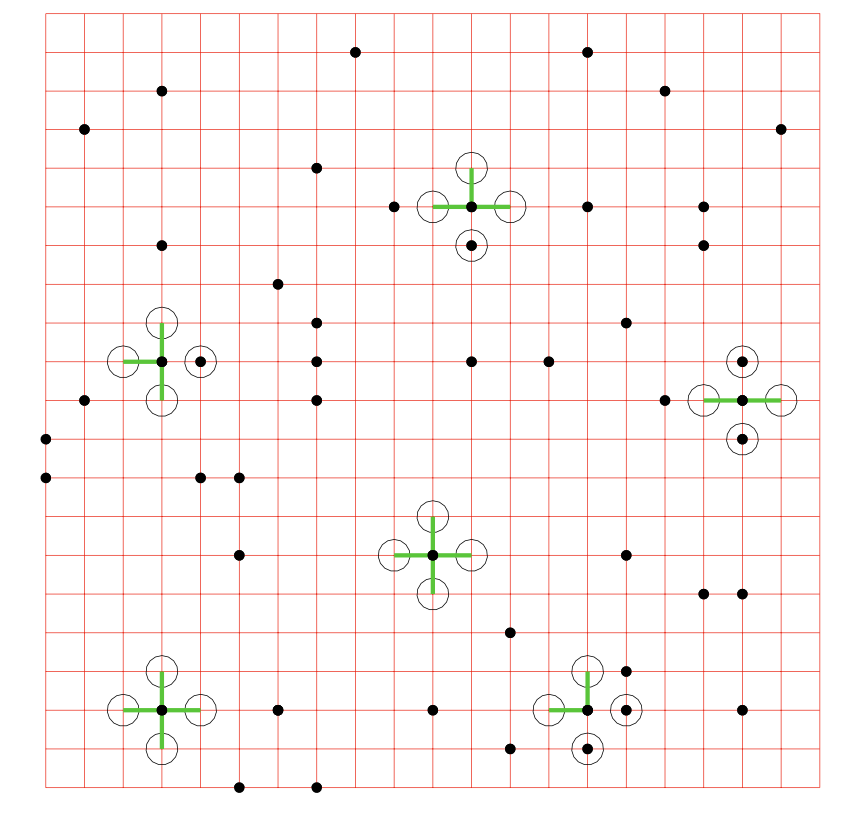

Example of 18 steps for a random walker every angle is random 

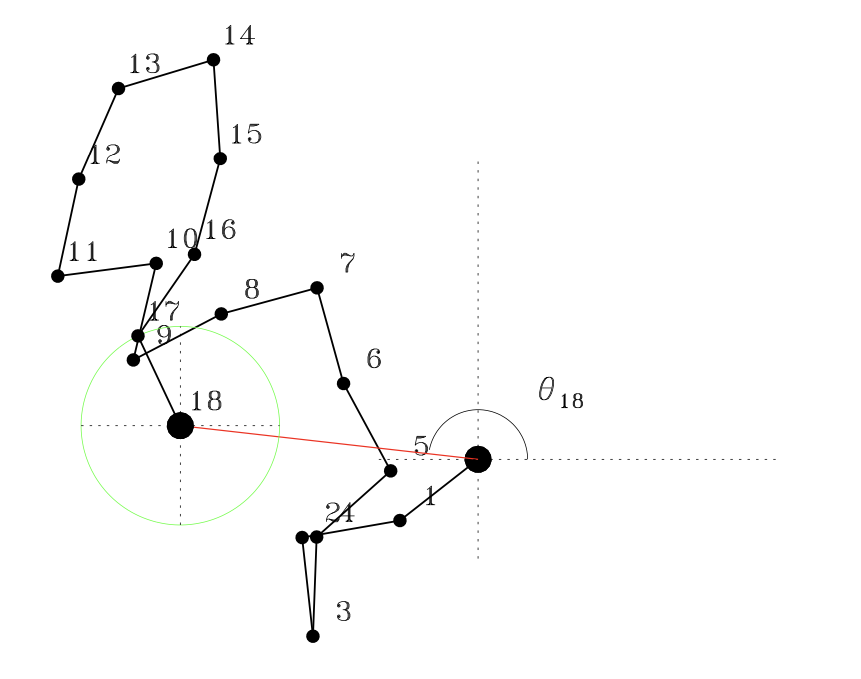

# Example of random walker 

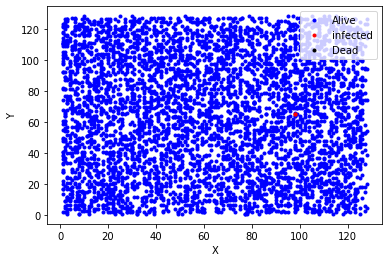

iter 0: 2 infected, 0 dead


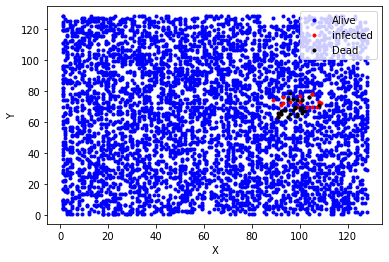

iter 50: 20 infected, 27 dead


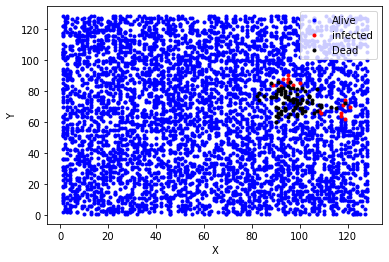

iter 100: 18 infected, 84 dead


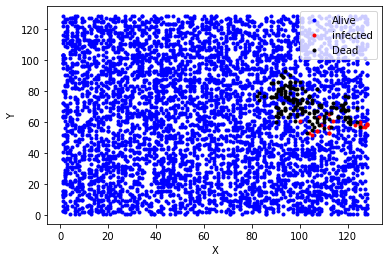

iter 150: 21 infected, 139 dead


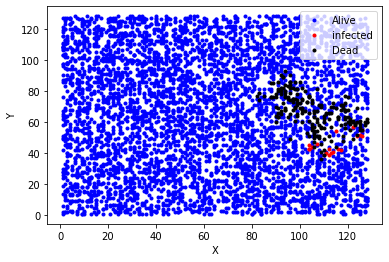

iter 200: 19 infected, 188 dead


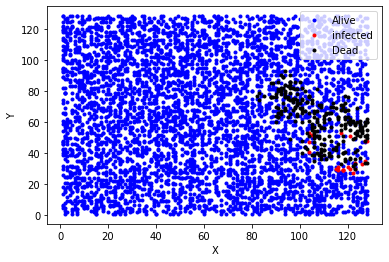

iter 250: 22 infected, 243 dead


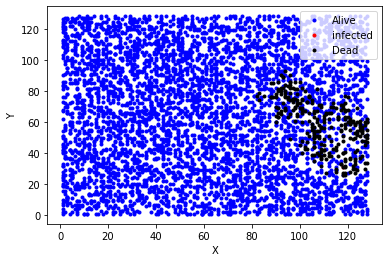

iter 300: 1 infected, 273 dead


In [23]:
import numpy as np
import matplotlib.pyplot as plt
M=5000
L=20

N=128  #Number of humans walking  
nIterMax=5000 #Maximal number of iteration
np.random.seed() #To specify the randomness use
nbDead=[] # 
nbin=[] 
nbalive=[]
x=np.random.randint(1,N,M) # Initial position
y=np.random.randint(1,N,M)
infect=np.zeros(M,dtype='int')     # status (0: healthy, 1: infected, 2: dead
survive=np.zeros(M,dtype='int')  
   # Time that they stay alive
jj=np.random.randint(0,M-1)  # Random selectionbc
infect[jj]=1 # He is not infected
survive[jj]=L # survival time

nInfect=1    # Number of initially infected walkers
nDead=0      # Number of dead 
itera=0    


while (nInfect>0) and (itera<nIterMax):
        v,=(infect<2).nonzero() # alive
        step=np.random.randint(1,5,v.size) #  random motion
        x1=np.zeros(v.size) # random size
        y1=np.zeros(v.size)
        Direction1=np.where(step==1) # in which direction 
        Direction2=np.where(step==2)
        Direction3=np.where(step==3)
        Direction4=np.where(step==4)
        
        x1[Direction1]+=1 # right
        y1[Direction1]+=0 # left
        
        x1[Direction2]-=1 # up
        y1[Direction2]+=0 #down
        
        
        x1[Direction3]+=0 # 
        y1[Direction3]-=1
        
        x1[Direction4]+=0
        y1[Direction4]+=1 #
        x[v]=np.clip(x[v]+x1,1,N)     # Have to stay within and motion
        y[v]=np.clip(y[v]+y1,1,N)     

          
        for j in (infect==1).nonzero()[0]:    # Infected
             k,=((x==x[j])&(y==y[j])&(infect==0)).nonzero() # Who is not infected
          
             if k.size>0:  # Check to see if infected people
                infect[k]=1 #infecting 
                nInfect+=k.size # 
                survive[k]=L # survival time 
         
             survive[j]-=1 #
        
             if survive[j]==0: # survival time
              infect[j]=2 # change of status
           
              nDead+=infect[j].size # add
              nInfect-=infect[j].size # update infected
             
        nbin.append(nInfect) # update
      
        nbDead.append(nDead)
        nbalive.append(M-nDead-nInfect) 
        
        # Plot
        if (itera%50)==0: 
            t=np.where(infect==0)[0]
            u=np.where(infect==1)[0]
            o=np.where(infect==2)[0]
            plt.plot(x[t],y[t],'.b',label="Alive") 
            plt.plot(x[u],y[u],'.r',label="infected")
            plt.plot(x[o],y[o],'.k',label="Dead")
            plt.xlabel('X') 
            plt.ylabel('Y')
            plt.legend()
            plt.show()
            print("iter {}: {} infected, {} dead".format(itera,nInfect,nDead)) 
        itera+=1 
        

        

    

# Example to be done in the exercice : forest fires simulation 


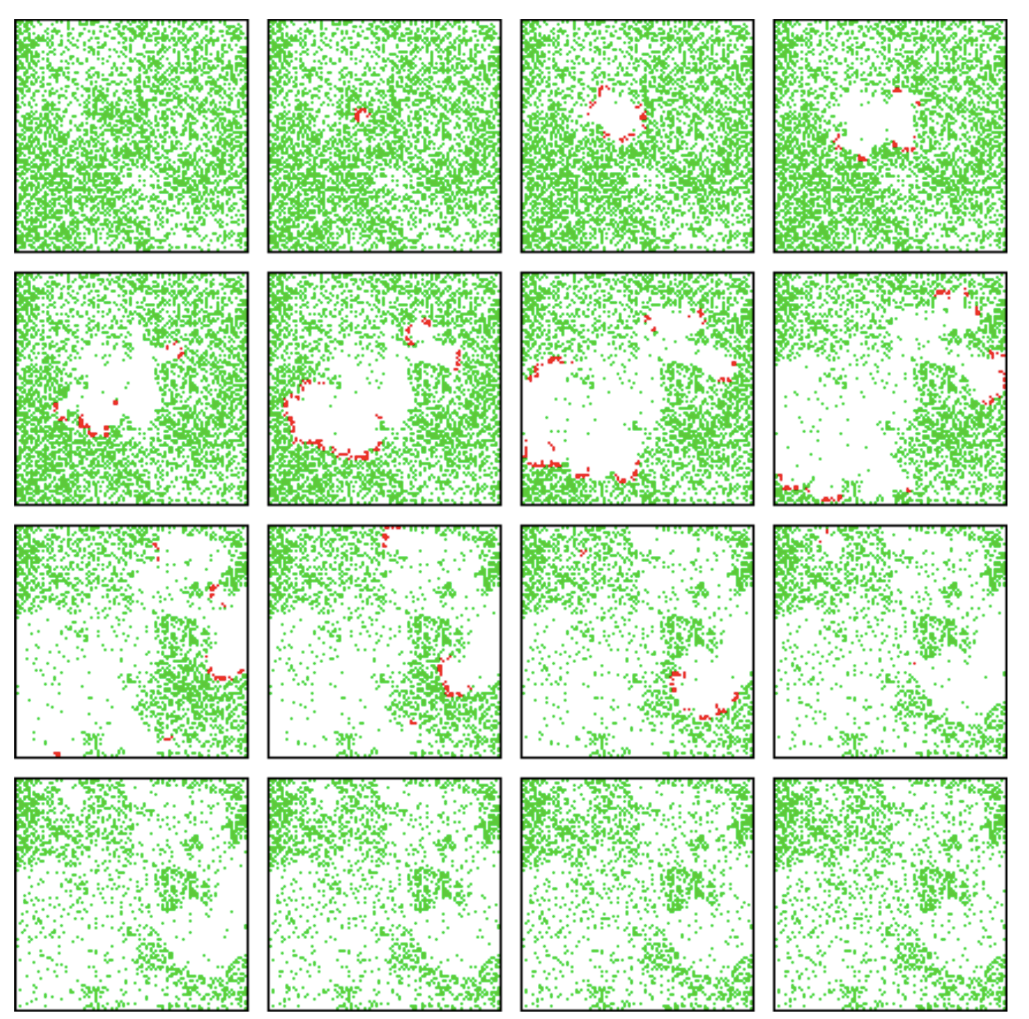

# Section 3: Scipy fitting 

Scipy is a package providing functionality for scientific calculations like:

- numerical integration
- minimization / curve fitting
- interpolation, e.g. splines
- statistical function, e.g. various probability distributions
- ...

 [Scipy Documentation](https://docs.scipy.org/doc/scipy/tutorial/index.html)

In [11]:
from scipy.optimize import curve_fit 
from numpy import random
import matplotlib.pyplot as plt
import numpy as np

In [13]:
def gaussian(x, a, mu, sigma): # Define function 
    """
    General Gaussian function 
    """
    return a * np.exp(-((x - mu) ** 2) / (2 * sigma**2))

In [45]:
help(curve_fit)

Help on function curve_fit in module scipy.optimize._minpack_py:

curve_fit(f, xdata, ydata, p0=None, sigma=None, absolute_sigma=False, check_finite=None, bounds=(-inf, inf), method=None, jac=None, *, full_output=False, nan_policy=None, **kwargs)
    Use non-linear least squares to fit a function, f, to data.
    
    Assumes ``ydata = f(xdata, *params) + eps``.
    
    Parameters
    ----------
    f : callable
        The model function, f(x, ...). It must take the independent
        variable as the first argument and the parameters to fit as
        separate remaining arguments.
    xdata : array_like
        The independent variable where the data is measured.
        Should usually be an M-length sequence or an (k,M)-shaped array for
        functions with k predictors, and each element should be float
        convertible if it is an array like object.
    ydata : array_like
        The dependent data, a length M array - nominally ``f(xdata, ...)``.
    p0 : array_like, optional

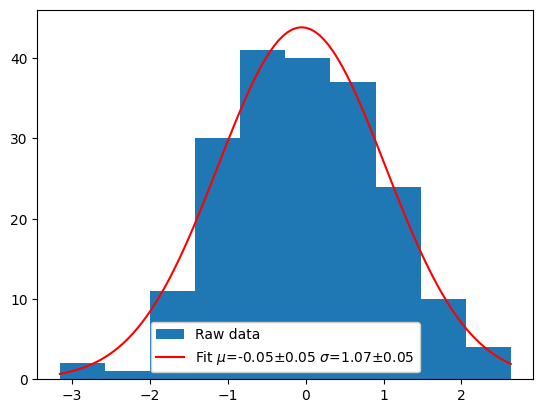

In [ ]:
#Step 1 generate a random distribution 
k=random.normal(size=200,loc=0,scale=1) #Fix the mean and the width of the gaussian 
plt.hist(k,label="Raw data") # Simply check what it looks like
counts, bins = np.histogram(k)#Bin the data
x_fit = bins[:-1] + np.diff(bins)[0] / 2 # Adjust the number of bins with number of counts

popt,pcov=curve_fit(gaussian,x_fit,counts,p0=[np.max(counts),0,0.3]) # Make the fit
err=np.sqrt(np.diag(pcov)) #Calculate the error
x_th=np.linspace(np.min(bins),np.max(bins),100) # Fit in high resolution
plt.plot(x_th,gaussian(x_th,*popt),'r',label=r"Fit $\mu$="+format(popt[1],'.2f')+"$\pm$"+format(err[1],'.2f')+" $\sigma$="+format(popt[2],'.2f')+"$\pm$"+format(err[2],'.2f'))
plt.legend(frameon=1,framealpha=1)


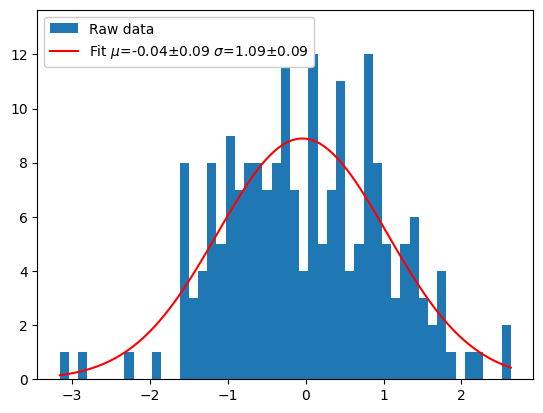

In [43]:
plt.hist(k,label="Raw data",bins=np.linspace(np.min(k),np.max(k),50)) # Simply increasing or changing the number of bins will have an effect on the fit
counts, bins = np.histogram(k,bins=np.linspace(np.min(k),np.max(k),50))
x_fit = bins[:-1] + np.diff(bins)[0] / 2

popt,pcov=curve_fit(gaussian,x_fit,counts,p0=[np.max(counts),0,0.3])
err=np.sqrt(np.diag(pcov)) 
x_th=np.linspace(np.min(bins),np.max(bins),100)
plt.plot(x_th,gaussian(x_th,*popt),'r',label=r"Fit $\mu$="+format(popt[1],'.2f')+"$\pm$"+format(err[1],'.2f')+" $\sigma$="+format(popt[2],'.2f')+"$\pm$"+format(err[2],'.2f'))
plt.legend(frameon=1,framealpha=1)

# Scipy Interpolation

1.0377963500742826
1.5393975777236688
4.07375746156322


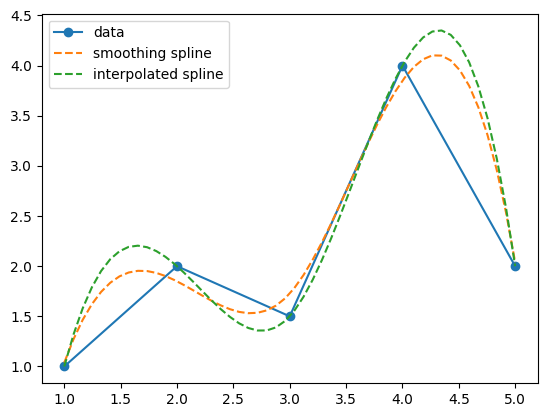

In [ ]:
from scipy import interpolate
# some data points in x and y
x = [1,2,3,4,5]
y = [1,2,1.5,4,2]

# we call some of the Spline classes of the interpolate package of scipy
spl = interpolate.UnivariateSpline(x, y, k=3, s=0.1) # this is a smoothing spline
spl2 = interpolate.InterpolatedUnivariateSpline(x, y, k=3) # this is an interpolation splinexw
# they return a funcion

print(spl(1)) # you can call them like a normal function
print(spl(1.2))
print(spl(4.2))

# ... and we can plot the results
# first, the raw data
plt.plot(x, y, "o-", label="data")

# then, we generate some sequential x values to evaluate the splines
xi = np.linspace(1,5)
# .. then we plot the evaluated splines
plt.plot(xi, spl(xi), "--", label="smoothing spline") # spline doesn't need to run through data points
plt.plot(xi, spl2(xi), "--", label="interpolated spline") # spline interpolates between data points, no smoothing
plt.legend()

# Fit a probability density function (PDF) to a gaussian distribution

fit parameter:  (5.017482765353496, 2.9624486176898333)


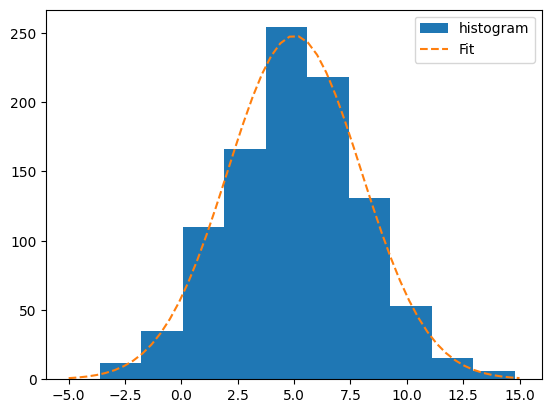

In [46]:
from scipy import stats
G = stats.norm # you need the 'un-fixed' function for fitting
G_frozen = G(loc=5, scale=3) # this is an 'rv_frozen' function, with fixed parameters

rn = G_frozen.rvs(size=1000) # random number generation with 'rvs' function (all stats functions have it)
h, edges, _ = plt.hist(rn, label="histogram")
fit = G.fit(rn)
print("fit parameter: ", fit)
x = np.linspace(-5, 15)
# we need to normalize the pdf to match the counts
y = G(*fit).pdf(x) * len(rn) * (edges[1] - edges[0])

plt.plot(x, y, "--", label="Fit")
plt.legend()

For more exercice https://sbu-python-class.github.io/python-science/05-scipy/scipy.html